In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn
from sklearn.model_selection import GroupKFold,cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [19]:
cols = ['unit', 'cycle', 'op1', 'op2', 'op3'] + [f's{i}' for i in range(1, 22)]
train = pd.read_csv('data/train_FD001.txt', sep=r'\s+', header=None, names=cols)
train.head()

,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [20]:
train["unit"].unique()

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100])

In [21]:
max_cycle=train.groupby('unit')['cycle'].transform('max')
train['RUL']=max_cycle-train['cycle']
train[['unit','cycle','RUL']].head()
train.head()
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 27 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   unit    20631 non-null  int64  
 1   cycle   20631 non-null  int64  
 2   op1     20631 non-null  float64
 3   op2     20631 non-null  float64
 4   op3     20631 non-null  float64
 5   s1      20631 non-null  float64
 6   s2      20631 non-null  float64
 7   s3      20631 non-null  float64
 8   s4      20631 non-null  float64
 9   s5      20631 non-null  float64
 10  s6      20631 non-null  float64
 11  s7      20631 non-null  float64
 12  s8      20631 non-null  float64
 13  s9      20631 non-null  float64
 14  s10     20631 non-null  float64
 15  s11     20631 non-null  float64
 16  s12     20631 non-null  float64
 17  s13     20631 non-null  float64
 18  s14     20631 non-null  float64
 19  s15     20631 non-null  float64
 20  s16     20631 non-null  float64
 21  s17     20631 non-null  int64  
 22  s18     2

In [22]:
train.describe().T[['mean','std']]

,mean,std
unit,51.506568,2.922763e+01
cycle,108.807862,6.888099e+01
op1,-0.000009,2.187313e-03
op2,0.000002,2.930621e-04
op3,100.000000,0.000000e+00
s1,518.670000,0.000000e+00
s2,642.680934,5.000533e-01
s3,1590.523119,6.131150e+00
s4,1408.933782,9.000605e+00
s5,14.620000,5.329200e-15


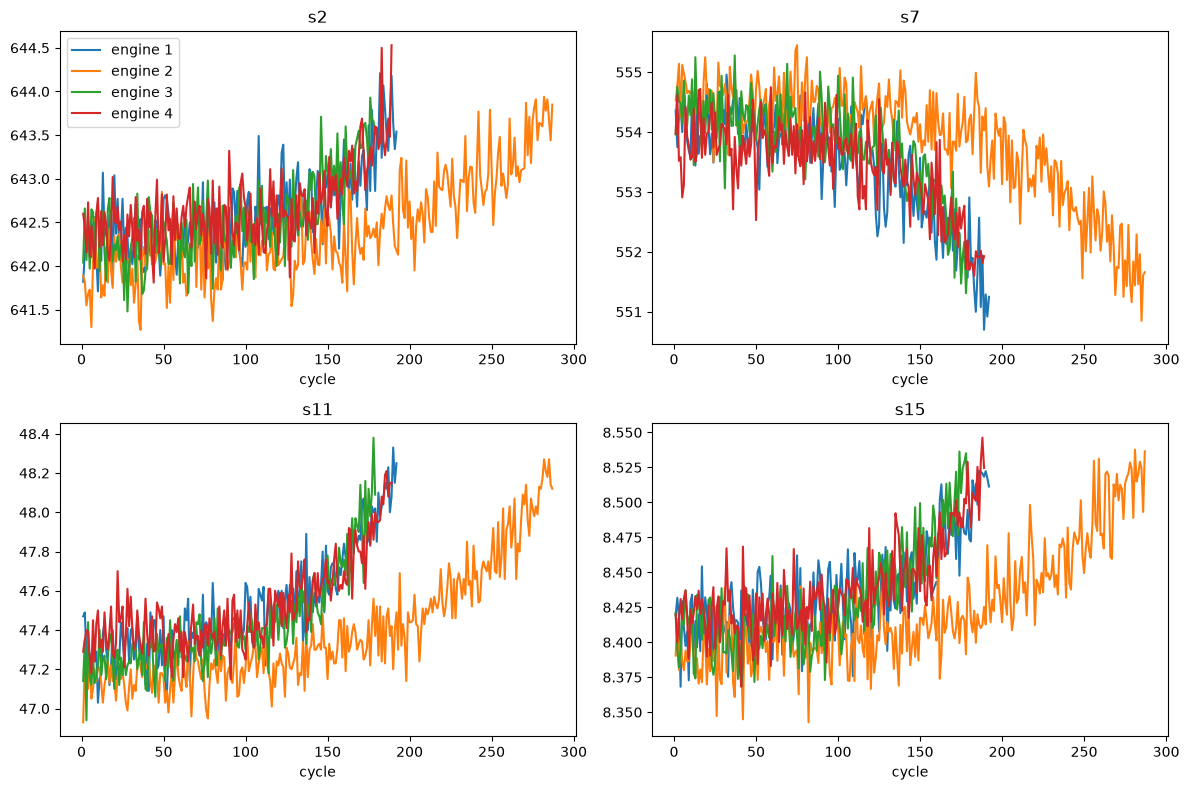

In [23]:
fig, axes=plt.subplots(2,2,figsize=(12,8))
for ax, s in zip(axes.flat,['s2','s7','s11','s15']):
    for u in [1,2,3,4]:
        d=train[train.unit==u]
        ax.plot(d['cycle'],d[s],label=f'engine {u}')
    ax.set_title(s)
    ax.set_xlabel('cycle')
axes[0,0].legend()
plt.tight_layout()
plt.show()
        

In [24]:
flat=[c for c in train.columns if c.startswith('s') and train[c].std() < 1e-6]
print(flat)

['s1', 's5', 's10', 's16', 's18', 's19']


In [25]:
train=train.drop(columns=flat,errors='ignore')
train['RUL']=train['RUL'].clip(upper=125)
sensors=[c for c in train.columns if c.startswith('s') and not c.endswith('_roll')]
for s in sensors:
    train[f'{s}_roll']=train.groupby('unit')[s].transform(lambda x:x.rolling(10,min_periods=1).mean())
train.shape

(20631, 36)

In [26]:
print(train.columns.tolist())

['unit', 'cycle', 'op1', 'op2', 'op3', 's2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21', 'RUL', 's2_roll', 's3_roll', 's4_roll', 's6_roll', 's7_roll', 's8_roll', 's9_roll', 's11_roll', 's12_roll', 's13_roll', 's14_roll', 's15_roll', 's17_roll', 's20_roll', 's21_roll']


In [28]:
train=train.drop(columns=['op3'],errors='ignore')

In [29]:
train.shape

(20631, 35)

In [30]:
feature_cols=[c for c in train.columns if c not in ['unit','cycle','RUL']]
X=train[feature_cols]
y=train['RUL']
groups=train['unit']
print(len(feature_cols))

32


In [37]:
models={
    "LR": LinearRegression(),
    "RF": RandomForestRegressor(n_estimators=101,max_depth=4,random_state=42),
    "XGB": XGBRegressor(max_depth=4,learning_rate=0.1,n_estimators=101,random_state=42)
}

In [38]:
group_kfold=GroupKFold(n_splits=5)

In [41]:
for name,model in models.items():
    preds=cross_val_predict(model,X,y,groups=groups,cv=group_kfold)
    rmse=np.sqrt(mean_squared_error(y,preds))
    mae=mean_absolute_error(y,preds)
    print(f"{name}: RMSE={rmse:.2f},MAE={mae:.2f}")

LR: RMSE=21.18,MAE=17.23
RF: RMSE=19.83,MAE=14.89
XGB: RMSE=18.80,MAE=13.50


In [42]:
test=pd.read_csv("data/test_FD001.txt",header=None,names=cols,sep=r'\s+')
rul_true=pd.read_csv("data/RUL_FD001.txt",header=None,names=['RUL'])

test=test.drop(columns=flat+['op3'],errors='ignore')

for s in sensors:
    test[f'{s}_roll']=test.groupby('unit')[s].transform(lambda x:x.rolling(10,min_periods=1).mean())

test_last=test.groupby('unit').tail(1)
X_test=test_last[feature_cols]

In [43]:
y_test=rul_true['RUL'].clip(upper=125)

for name,model in models.items():
    model.fit(X,y)
    p=model.predict(X_test)
    rmse=np.sqrt(mean_squared_error(y_test,p))
    mae=mean_absolute_error(y_test,p)
    print(f"{name}: RMSE={rmse:.2f},MAE={mae:.2f}")

LR: RMSE=20.78,MAE=16.35
RF: RMSE=20.51,MAE=14.11
XGB: RMSE=18.61,MAE=13.16


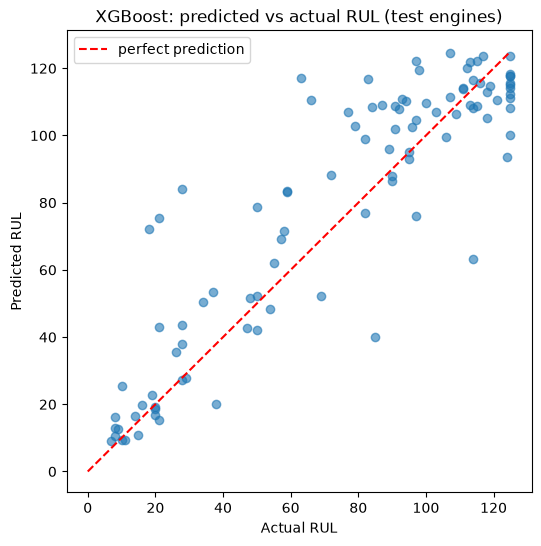

In [45]:
p = models['XGB'].predict(X_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, p, alpha=0.6)

plt.plot([0, 125], [0, 125], 'r--', label='perfect prediction')
plt.xlabel('Actual RUL')
plt.ylabel('Predicted RUL')
plt.title('XGBoost: predicted vs actual RUL (test engines)')
plt.legend()
plt.savefig('../rul_pred_vs_actual.png', dpi=150, bbox_inches='tight')
plt.show()

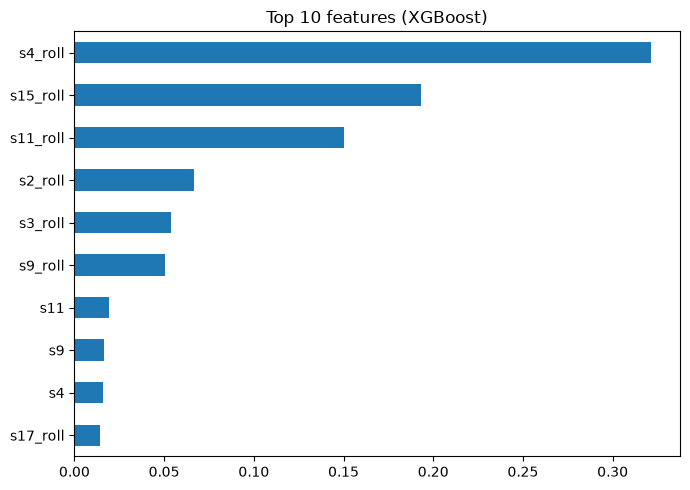

In [47]:
imp = pd.Series(models['XGB'].feature_importances_, index=feature_cols).sort_values()
imp.tail(10).plot(kind='barh', figsize=(7, 5), title='Top 10 features (XGBoost)')
plt.tight_layout()
plt.savefig('../feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()